# Chapitre 6 - Cours 3 : points chauds et routage des requêtes

Les cours 1 et 2 ont réparti des **clés** équitablement. Ce notebook aborde deux
questions qui restent : que faire quand quelques clés reçoivent l'essentiel des
**requêtes** (le compte d'une célébrité, un message devenu viral) ? Et comment une
requête trouve-t-elle la partition, donc le nœud, qui détient sa
clé, alors même que les morceaux se déplacent ? Il couvre les sections *Skewed Workloads
and Relieving Hot Spots* et *Request Routing* (avec *Parallel Query Execution*).

**Plan.**

1. Le hachage répartit les clés, pas la charge : requêtes en loi de Zipf.
2. La célébrité : une clé chaude qui dure quelques heures.
3. Saler les clés chaudes : éclater les écritures, payer à la lecture.
4. Isoler une clé chaude, et distinguer lectures et écritures.
5. Trois façons de router une requête.
6. Qui détient la carte ? Coordinateur, notifications et diffusion épidémique.
7. Les requêtes qui touchent tous les morceaux : exécution parallèle.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import partitioning as P
from ddia.diagrams import Diagram
from ddia.timelines import SpaceTime
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## 1. Le hachage répartit les clés, pas la charge (section *Skewed Workloads and Relieving Hot Spots*)

Le hachage garantit que chaque morceau reçoit à peu près **le même nombre de clés**. Mais
si certaines clés sont beaucoup plus demandées que d'autres, la **charge** reste
déséquilibrée. Les popularités réelles suivent souvent une **loi de Zipf** : la clé de
rang $r$ reçoit une part proportionnelle à $1/r^s$. Avec $s = 1$ et 100 000 clés, la clé
la plus demandée attire à elle seule $1/H_{100\,000} \approx 8\,\%$ des requêtes
($H_n = \sum_{r \le n} 1/r \approx \ln n + 0{,}58$).

Calculons la charge exacte de 16 morceaux (clés placées par hachage) selon l'exposant
$s$.

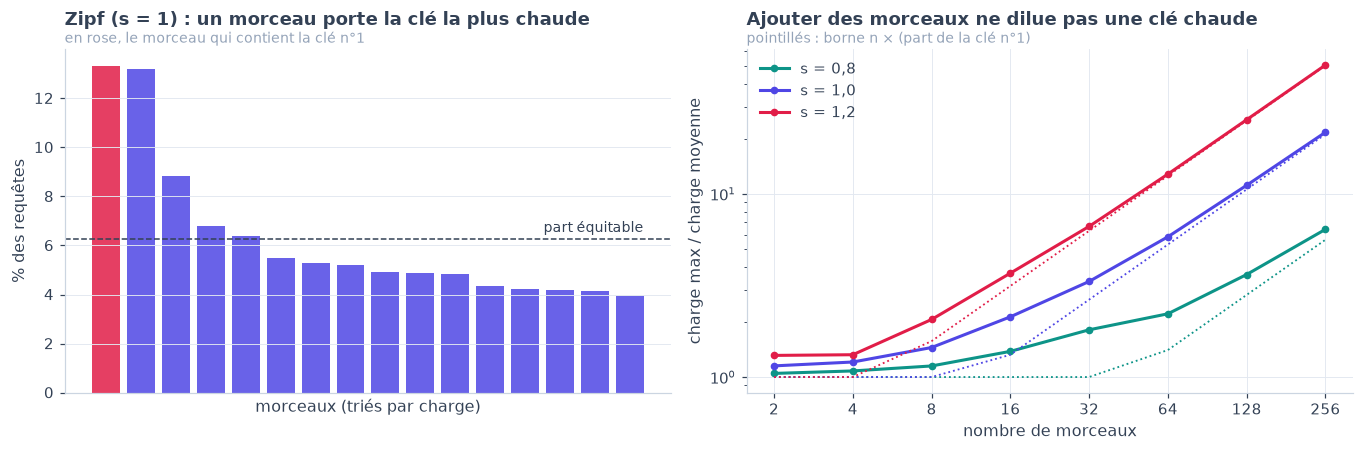

,part de la clé n°1,part des 100 premières,déséquilibre des morceaux
exposant s,,,
0.0,1.000e-05,0.001,1.026
0.6,4.031e-03,0.056,1.091
0.8,2.195e-02,0.179,1.381
1.0,8.271e-02,0.429,2.132
1.2,1.964e-01,0.708,3.692


In [2]:
N_KEYS, N_SH = 100_000, 16
keys = np.arange(N_KEYS)
shard_of_key = (P.hash_unit(keys) * N_SH).astype(int)
rows, loads_by_s = [], {}
for s in [0.0, 0.6, 0.8, 1.0, 1.2]:
    w = P.zipf_weights(N_KEYS, s)
    loads = P.shard_loads(shard_of_key, N_SH, weights=w)
    loads_by_s[s] = loads
    rows.append({"exposant s": s, "part de la clé n°1": w[0], "part des 100 premières": w[:100].sum(),
                 "déséquilibre des morceaux": P.imbalance(loads)})
zipf_tab = pd.DataFrame(rows).set_index("exposant s")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
ax = axes[0]
order = np.argsort(-loads_by_s[1.0])
hot_shard = shard_of_key[0]
cols = [ROSE if i == hot_shard else INDIGO for i in order]
ax.bar(range(N_SH), loads_by_s[1.0][order] * 100, color=cols, alpha=0.85)
ax.axhline(100 / N_SH, color=SLATE, ls="--", lw=1); ax.text(15.4, 100 / N_SH + 0.3, "part équitable", ha="right", fontsize=9)
ax.set_xlabel("morceaux (triés par charge)"); ax.set_ylabel("% des requêtes")
ax.set_title("Zipf (s = 1) : un morceau porte la clé la plus chaude")
subtitle(ax, "en rose, le morceau qui contient la clé n°1")
ax.set_xticks([])
ax = axes[1]
ns = [2, 4, 8, 16, 32, 64, 128, 256]
for s, c in [(0.8, TEAL), (1.0, INDIGO), (1.2, ROSE)]:
    w = P.zipf_weights(N_KEYS, s)
    imb = [P.imbalance(P.shard_loads((P.hash_unit(keys) * n).astype(int), n, weights=w)) for n in ns]
    ax.plot(ns, imb, "o-", color=c, ms=4, label=f"s = {s}".replace(".", ","))
    ax.plot(ns, np.maximum(1, w[0] * np.array(ns)), ":", color=c, lw=1.2)
ax.set_xscale("log", base=2); ax.set_xticks(ns); ax.set_xticklabels(ns); ax.set_yscale("log")
ax.set_xlabel("nombre de morceaux"); ax.set_ylabel("charge max / charge moyenne")
ax.set_title("Ajouter des morceaux ne dilue pas une clé chaude")
subtitle(ax, "pointillés : borne n × (part de la clé n°1)")
ax.legend()
plt.tight_layout(); plt.show()
zipf_tab

Avec $s = 1$, le morceau qui contient la clé n°1 reçoit environ 13 % des requêtes, plus du
double de sa part équitable (6,25 %). Surtout, le graphique de droite montre que
**multiplier les morceaux n'y change rien** : la clé n°1 ne peut pas être coupée, si bien
que son morceau porte au moins $w_1$ de la charge totale, et le déséquilibre croît comme
$n \times w_1$ (pointillés). Avec 256 morceaux et $s = 1{,}2$, le morceau chaud reçoit
environ 50 fois la moyenne. Le hachage cohérent, si parfait soit-il, ne règle pas ce problème.

> **À retenir.** Le hachage équilibre le nombre de clés, pas leur popularité. Une clé
> chaude fixe un plancher de charge à son morceau, que l'ajout de nœuds ne fait pas
> baisser : $\text{déséquilibre} \ge n \cdot w_1$.

## 2. La célébrité : une clé chaude éphémère (section *Skewed Workloads and Relieving Hot Spots*)

Sur un réseau social, un message d'une personne suivie par des millions de comptes
déclenche une **tempête d'activité** : lectures, réponses, « j'aime », toutes adressées à
la même clé (l'identifiant du message ou de son auteur). Ce pic est **éphémère** : intense
pendant quelques heures, il retombe en un ou deux jours. Modélisons le débit sur la clé
par une montée rapide suivie d'une décroissance exponentielle, au-dessus de la charge de
fond du morceau, et comparons-le à la capacité d'un nœud.

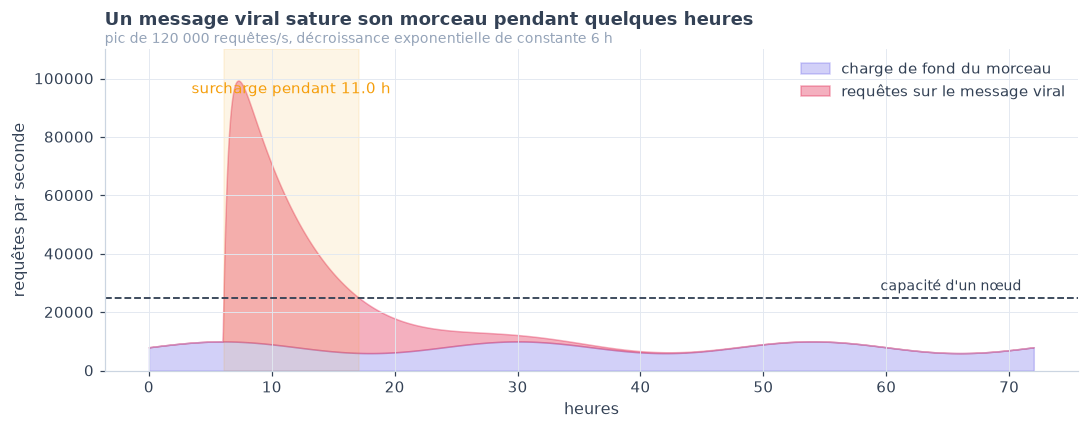

In [3]:
hours = np.linspace(0, 72, 2_000)
t0, rise, tau = 6.0, 0.5, 6.0
viral = np.where(hours < t0, 0, 120_000 * (1 - np.exp(-(hours - t0) / rise)) * np.exp(-(hours - t0) / tau))
background = 8_000 + 2_000 * np.sin(2 * np.pi * hours / 24)
capacity = 25_000
total = background + viral
over = hours[total > capacity]
fig, ax = plt.subplots(figsize=(10, 4))
ax.fill_between(hours, 0, background, color=INDIGO, alpha=0.25, label="charge de fond du morceau")
ax.fill_between(hours, background, total, color=ROSE, alpha=0.35, label="requêtes sur le message viral")
ax.axhline(capacity, color=SLATE, ls="--", lw=1.2); ax.text(71, capacity + 2500, "capacité d'un nœud", ha="right", fontsize=9)
ax.axvspan(over.min(), over.max(), color=AMBER, alpha=0.1)
ax.text((over.min() + over.max()) / 2, 95_000, f"surcharge pendant {over.max() - over.min():.1f} h", ha="center", color=AMBER, fontsize=9.5)
ax.set_xlabel("heures"); ax.set_ylabel("requêtes par seconde"); ax.set_ylim(0, 110_000)
ax.set_title("Un message viral sature son morceau pendant quelques heures")
subtitle(ax, "pic de 120 000 requêtes/s, décroissance exponentielle de constante 6 h")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

Le morceau qui héberge la clé est saturé pendant onze heures, puis tout redevient
normal. Deux difficultés en découlent : la charge **change dans le temps** (une clé
chaude aujourd'hui sera froide demain, une autre le deviendra), et une clé peut être
chaude **en lecture** (tout le monde lit le message) ou **en écriture** (tout le monde le
commente ou l'aime), ce qui appelle des remèdes différents (sections 3 et 4).

> **À retenir.** Les clés chaudes sont souvent imprévisibles et éphémères ; il faut
> pouvoir les détecter, les traiter à part, puis revenir à la normale.

## 3. Saler les clés chaudes (section *Skewed Workloads and Relieving Hot Spots*)

**La technique.** Pour une clé chaude **en écriture**, l'application ajoute un nombre
aléatoire au début ou à la fin de la clé : avec deux chiffres, les écritures sur
`post:42` se répartissent sur `post:42#00` à `post:42#99`, cent clés qui atterrissent
dans des morceaux différents. **Le prix** : toute lecture doit désormais interroger les
cent sous-clés et combiner leurs valeurs. Et ce n'est utile que pour les rares clés
chaudes : il faut tenir un **registre** des clés salées et un moyen d'y faire entrer (et
sortir) une clé.

Dimensionnons : 60 000 écritures/s sur une clé, 64 morceaux recevant chacun 4 000
écritures/s de fond, une capacité de 10 000 écritures/s par morceau. Avec $k$ sous-clés,
chaque sous-clé reçoit $60\,000/k$ écritures/s, mais deux sous-clés peuvent tomber dans
le même morceau (balles dans des urnes, cours 1).

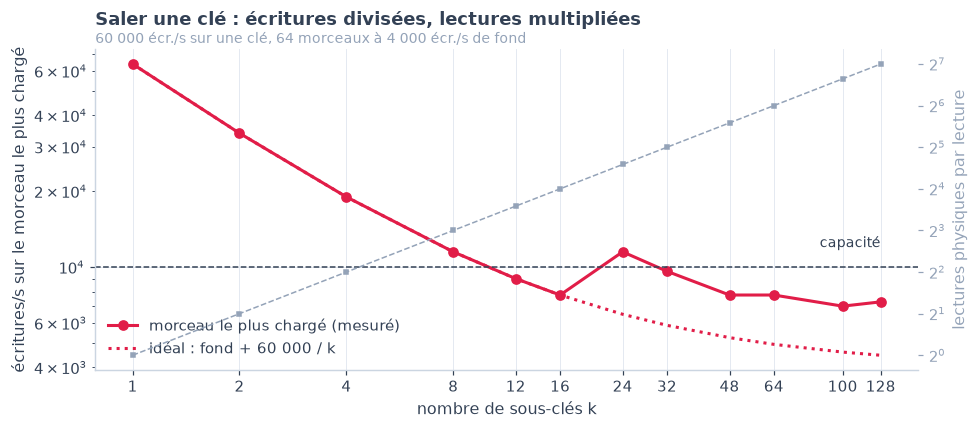

k,1,2,4,8,12,16,24,32,48,64,100,128
charge max (écr./s),64000.0,34000.0,19000.0,11500.0,9000.0,7750.0,11500.0,9625.0,7750.0,7750.0,7000.0,7281.25
morceaux touchés,1.0,2.0,4.0,8.0,12.0,16.0,18.0,23.0,36.0,41.0,52.0,57.00
lectures par lecture logique,1.0,2.0,4.0,8.0,12.0,16.0,24.0,32.0,48.0,64.0,100.0,128.00


In [4]:
W_HOT, N64, BG, CAP = 60_000, 64, 4_000, 10_000
ks = [1, 2, 4, 8, 12, 16, 24, 32, 48, 64, 100, 128]
res = []
for k in ks:
    sub = P.salted_variants("post:42", k)
    shard = np.array([P.stable_hash(x) % N64 for x in sub])
    per_shard = np.bincount(shard, minlength=N64) * W_HOT / k + BG
    res.append({"k": k, "charge max (écr./s)": per_shard.max(), "morceaux touchés": len(set(shard)),
                "lectures par lecture logique": k})
salt = pd.DataFrame(res)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(salt["k"], salt["charge max (écr./s)"], "o-", color=ROSE, label="morceau le plus chargé (mesuré)")
ax.plot(salt["k"], BG + W_HOT / salt["k"], ":", color=ROSE, label="idéal : fond + 60 000 / k")
ax.axhline(CAP, color=SLATE, ls="--", lw=1); ax.text(128, CAP + 2_000, "capacité", ha="right", fontsize=9)
ax.set_xscale("log", base=2); ax.set_xticks(ks); ax.set_xticklabels(ks); ax.set_yscale("log")
ax.set_xlabel("nombre de sous-clés k"); ax.set_ylabel("écritures/s sur le morceau le plus chargé")
ax2 = ax.twinx(); ax2.plot(salt["k"], salt["k"], "s--", color=GRAY, ms=3, lw=1); ax2.set_ylabel("lectures physiques par lecture", color=GRAY)
ax2.set_yscale("log", base=2); ax2.grid(False); ax2.tick_params(axis="y", colors=GRAY)
ax.set_title("Saler une clé : écritures divisées, lectures multipliées")
subtitle(ax, "60 000 écr./s sur une clé, 64 morceaux à 4 000 écr./s de fond")
ax.legend(loc="lower left")
plt.tight_layout(); plt.show()
salt.set_index("k").T

Il faut au moins $60\,000 / (10\,000 - 4\,000) = 10$ sous-clés en théorie ; la capacité
est respectée pour $k = 12$ et $16$ dans ce tirage, mais **pas** pour $k = 24$ : trois
sous-clés tombent alors dans le même morceau (11 500 écritures/s). Les collisions de
hachage (balles dans des urnes, cours 1) imposent soit de vérifier le placement des
sous-clés, soit de prendre une large marge ($k \ge 48$ ici). En contrepartie, chaque lecture du
compteur de « j'aime » coûte des dizaines de lectures physiques au lieu d'une : la charge en
**lecture** sur chaque sous-clé n'est pas réduite, seule l'écriture est divisée.

Une implémentation minimale du registre montre la mécanique : un compteur salé reste
exact, mais sa lecture rassemble toutes les sous-clés.

In [5]:
class SaltedCounters:
    """Compteurs dont les clés chaudes sont salées en n sous-clés (registre explicite)."""

    def __init__(self, n_shards=64, seed=0):
        self.store = [dict() for _ in range(n_shards)]
        self.n = n_shards
        self.hot = {}                                  # registre : clé -> nombre de sous-clés
        self.rng = np.random.default_rng(seed)
        self.writes = np.zeros(n_shards, dtype=int)
        self.reads = 0

    def _put(self, k, delta):
        s = P.stable_hash(k) % self.n
        self.store[s][k] = self.store[s].get(k, 0) + delta
        self.writes[s] += 1

    def incr(self, key):
        if key in self.hot:
            key = P.salted_key(key, int(self.rng.integers(self.hot[key])))
        self._put(key, 1)

    def get(self, key):
        subs = P.salted_variants(key, self.hot[key]) if key in self.hot else [key]
        self.reads += len(subs)
        return sum(self.store[P.stable_hash(k) % self.n].get(k, 0) for k in subs)

    def make_hot(self, key, n):
        """Fait entrer une clé dans le registre : son ancienne valeur devient la sous-clé 00."""
        old = self.store[P.stable_hash(key) % self.n].pop(key, 0)
        self.hot[key] = n
        self._put(P.salted_key(key, 0), old)


sc = SaltedCounters()
for _ in range(20_000):
    sc.incr("post:42")
w_before = sc.writes.max()
sc.make_hot("post:42", 16)
sc.writes[:] = 0
for _ in range(20_000):
    sc.incr("post:42")
print(f"compteur : {sc.get('post:42')} (attendu 40 000) ; lectures physiques pour une lecture : {sc.reads}")
print(f"écritures du morceau le plus sollicité : {w_before} sur 20 000 avant salage, {sc.writes.max()} après")

compteur : 40000 (attendu 40 000) ; lectures physiques pour une lecture : 16
écritures du morceau le plus sollicité : 20000 sur 20 000 avant salage, 1303 après


**Détecter les clés chaudes.** Pour alimenter le registre, il suffit souvent
d'**échantillonner** les requêtes : sur un flux Zipf, 1 % des requêtes suffit à retrouver
les clés les plus demandées.

In [6]:
reqs = P.zipf_requests(N_KEYS, 500_000, s=1.0, seed=4)
true_top = pd.Series(reqs).value_counts().head(10)
sample = reqs[rng.random(reqs.size) < 0.01]
est_top = pd.Series(sample).value_counts().head(10) * 100
pd.DataFrame({"clé (vrai top 10)": true_top.index, "requêtes réelles": true_top.values,
              "estimation sur 1 % (clé)": est_top.index, "requêtes estimées": est_top.values})

,clé (vrai top 10),requêtes réelles,estimation sur 1 % (clé),requêtes estimées
0,0,41540,0,36400
1,1,20756,1,22700
2,2,13654,2,14100
3,3,10296,3,9700
4,4,8263,4,7700
5,5,6973,6,7100
6,6,5858,5,7000
7,7,5156,8,5800
8,8,4702,7,5600
9,9,4104,9,5000


Les cinq premières clés sont retrouvées dans l'ordre, avec des effectifs estimés à 15 %
près ; au-delà, l'échantillon confond des clés de popularités
voisines, ce qui n'a pas d'importance : seules les toutes premières clés méritent un
traitement spécial.

> **À retenir.** Saler une clé chaude (suffixe aléatoire) divise sa charge d'écriture par
> le nombre de sous-clés, mais multiplie d'autant le coût des lectures et exige un registre
> des clés salées. À réserver aux quelques clés détectées comme chaudes en écriture.

## 4. Isoler une clé chaude, distinguer lectures et écritures (section *Skewed Workloads and Relieving Hot Spots*)

Un découpage par **plages** (de clés ou de hachés) permet une autre parade : placer une
clé chaude **seule dans son morceau**, voire sur une machine dédiée, et plus généralement
choisir les bornes pour que les clés chaudes se répartissent bien entre les nœuds. Mais si
une clé dépasse à elle seule la part d'une machine, la placer ne suffit pas. Comparons,
pour 16 nœuds et des requêtes Zipf ($s = 1$), la charge du nœud le plus chargé avec
plusieurs stratégies, selon que la clé chaude est chaude en **lecture** (on peut alors servir ses
lectures depuis plusieurs répliques ou un cache) ou en **écriture** (seul le salage
répartit les écritures).

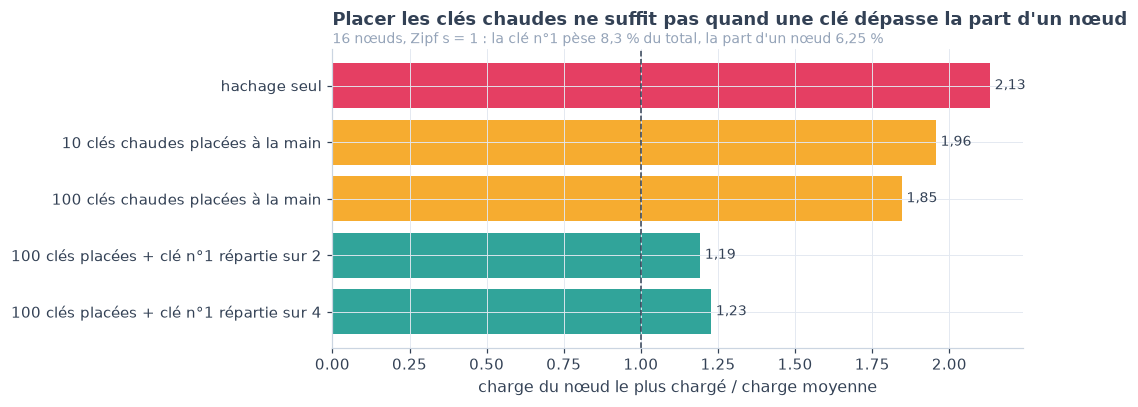

In [7]:
w = P.zipf_weights(N_KEYS, 1.0)
base_nodes = (P.hash_unit(keys) * 16).astype(int)

def max_node_load(explicit=0, split_top=1, n=16):
    """Charge du nœud le plus chargé (en multiples de la moyenne).

    Les clés au-delà des `explicit` premières sont placées par hachage ; les `explicit` clés
    les plus chaudes sont placées explicitement (bornes de plages ajustées), de la plus
    lourde à la plus légère, sur le nœud le moins chargé. La clé n°1 peut être répartie sur
    `split_top` nœuds (répliques pour les lectures, salage pour les écritures)."""
    loads = np.zeros(n)
    np.add.at(loads, base_nodes[explicit:], w[explicit:])
    if explicit == 0:
        loads[base_nodes[0]] -= w[0]
        targets = [base_nodes[0]] + [t for t in np.argsort(loads) if t != base_nodes[0]][: split_top - 1]
        for t in targets:
            loads[t] += w[0] / len(targets)
        return loads.max() * n
    for r in range(explicit):
        parts = split_top if r == 0 else 1
        for t in np.argsort(loads)[:parts]:
            loads[t] += w[r] / parts
    return loads.max() * n

strat = pd.DataFrame({
    "stratégie": ["hachage seul", "10 clés chaudes placées à la main", "100 clés chaudes placées à la main",
                  "100 clés placées + clé n°1 répartie sur 2", "100 clés placées + clé n°1 répartie sur 4"],
    "charge max / moyenne": [max_node_load(), max_node_load(10), max_node_load(100),
                             max_node_load(100, 2), max_node_load(100, 4)],
})
fig, ax = plt.subplots(figsize=(9.5, 3.8))
bars = ax.barh(strat["stratégie"], strat["charge max / moyenne"], color=[ROSE, AMBER, AMBER, TEAL, TEAL], alpha=0.85)
ax.axvline(1, color=SLATE, ls="--", lw=1)
ax.bar_label(bars, labels=[f"{v:.2f}".replace(".", ",") for v in strat["charge max / moyenne"]], padding=3, fontsize=9)
ax.invert_yaxis(); ax.set_xlabel("charge du nœud le plus chargé / charge moyenne")
ax.set_title("Placer les clés chaudes ne suffit pas quand une clé dépasse la part d'un nœud")
subtitle(ax, "16 nœuds, Zipf s = 1 : la clé n°1 pèse 8,3 % du total, la part d'un nœud 6,25 %")
plt.tight_layout(); plt.show()

Avec le hachage seul (2,13), le hasard place deux clés très chaudes sur le même nœud.
Placer à la main les clés les plus chaudes, chacune sur le nœud le moins chargé, n'aide
que peu (1,96 puis 1,85) : la clé n°1 pèse à elle seule 8,3 % du total, plus que la part
équitable d'un nœud (6,25 %), et le nœud qui la reçoit garde en plus sa part des autres
clés. Le plancher $16 \times 0{,}083 = 1{,}33$ est infranchissable tant que la clé reste
entière. Il faut **la répartir** : sur deux nœuds, le déséquilibre tombe à 1,19 ; sur
quatre, il ne baisse plus (1,23, le placement des autres clés devient le facteur
limitant). On répartit avec des répliques et un cache si la clé est chaude en lecture,
avec le salage si elle est chaude en
écriture. En pratique, le traitement des clés chaudes reste largement à la charge de
l'application ; la base ne sait pas, en général, compenser seule une charge très
asymétrique.

> **À retenir.** Un découpage par plages permet d'isoler une clé chaude, mais une clé
> plus lourde que la part d'un nœud doit être **répartie** : répliques et caches pour les
> lectures, salage pour les écritures.